# Simple baselines and logistic regression

This notebook compares a training window majority baseline, a direction persistence baseline, and Logistic Regression. A persistence forecast assumes the latest completed close to close direction continues into the next bar. Each test block follows its training dates, and the scaler is fit within each training fold. The target is the next bar open to close direction.


In [1]:
# Set paths and import the feature and expanding-window evaluation functions.
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import pandas_market_calendars as mcal

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(project_root / "python_code"))
from feature_engineering import FEATURE_COLUMNS, build_model_frame, select_scheduled_bars
from model_evaluation import evaluate_expanding_window
data_dir = project_root / "data"


In [2]:
# Rebuild model frames with scheduled bars and leakage-aware predictors.
qqq_source = pd.read_parquet(data_dir / "QQQ_clean_5min.parquet")
spy_source = pd.read_parquet(data_dir / "SPY_clean_5min.parquet")
start_date = min(qqq_source["datetime"].min(), spy_source["datetime"].min()).date()
end_date = max(qqq_source["datetime"].max(), spy_source["datetime"].max()).date()
schedule = mcal.get_calendar("NYSE").schedule(start_date=start_date, end_date=end_date)
qqq_model = build_model_frame(select_scheduled_bars(qqq_source, schedule))
spy_model = build_model_frame(select_scheduled_bars(spy_source, schedule))
assert set(FEATURE_COLUMNS).isdisjoint({"next_datetime", "next_close", "next_return", "target"})
print("Feature columns:", list(FEATURE_COLUMNS))


Feature columns: ['return_1_bar', 'return_3_bars', 'return_6_bars', 'realized_volatility_12_bars', 'bar_range_pct', 'close_location_in_bar', 'log_volume', 'log_volume_change_1_bar', 'minutes_since_open', 'time_of_day_sin', 'time_of_day_cos']


In [3]:
# Score the same three baseline/logistic approaches on five later test folds.
evaluation = {}
for name, frame in [("QQQ", qqq_model), ("SPY", spy_model)]:
    metrics, predictions = evaluate_expanding_window(
        frame, FEATURE_COLUMNS, initial_train_fraction=0.60, n_splits=5
    )
    metrics.insert(0, "ETF", name)
    predictions.insert(0, "ETF", name)
    evaluation[name] = {"metrics": metrics, "predictions": predictions}
    print(f"{name}: {len(metrics['fold'].unique())} folds; {len(predictions):,} out-of-sample rows")
    print(metrics[["fold", "model", "train_start", "train_end", "test_start", "test_end", "train_rows", "test_rows"]].to_string(index=False))


QQQ: 5 folds; 29,012 out-of-sample rows
 fold                          model train_start  train_end test_start   test_end  train_rows  test_rows
    1              Majority baseline  2022-03-07 2024-12-06 2024-12-09 2025-04-25       43169       5770
    1 Direction persistence baseline  2022-03-07 2024-12-06 2024-12-09 2025-04-25       43169       5770
    1            Logistic regression  2022-03-07 2024-12-06 2024-12-09 2025-04-25       43169       5770
    2              Majority baseline  2022-03-07 2025-04-25 2025-04-28 2025-09-09       48939       5819
    2 Direction persistence baseline  2022-03-07 2025-04-25 2025-04-28 2025-09-09       48939       5819
    2            Logistic regression  2022-03-07 2025-04-25 2025-04-28 2025-09-09       48939       5819
    3              Majority baseline  2022-03-07 2025-09-09 2025-09-10 2026-01-22       54758       5786
    3 Direction persistence baseline  2022-03-07 2025-09-09 2025-09-10 2026-01-22       54758       5786
    3          

SPY: 5 folds; 29,099 out-of-sample rows
 fold                          model train_start  train_end test_start   test_end  train_rows  test_rows
    1              Majority baseline  2022-03-07 2024-12-06 2024-12-09 2025-04-25       43049       5895
    1 Direction persistence baseline  2022-03-07 2024-12-06 2024-12-09 2025-04-25       43049       5895
    1            Logistic regression  2022-03-07 2024-12-06 2024-12-09 2025-04-25       43049       5895
    2              Majority baseline  2022-03-07 2025-04-25 2025-04-28 2025-09-09       48944       5756
    2 Direction persistence baseline  2022-03-07 2025-04-25 2025-04-28 2025-09-09       48944       5756
    2            Logistic regression  2022-03-07 2025-04-25 2025-04-28 2025-09-09       48944       5756
    3              Majority baseline  2022-03-07 2025-09-09 2025-09-10 2026-01-22       54700       5754
    3 Direction persistence baseline  2022-03-07 2025-09-09 2025-09-10 2026-01-22       54700       5754
    3          

In [4]:
# Summarize fold averages and pooled predictions for context.
fold_metrics = pd.concat([item["metrics"] for item in evaluation.values()], ignore_index=True)
display(fold_metrics.groupby(["ETF", "model"])[["accuracy", "balanced_accuracy", "f1_up", "roc_auc"]].agg(["mean", "std"]).round(4))

pooled_rows = []
for name, item in evaluation.items():
    pred = item["predictions"]
    for model_name, column in [("Majority baseline", "baseline_prediction"), ("Direction persistence baseline", "persistence_prediction"), ("Logistic regression", "logistic_prediction")]:
        pooled_rows.append({
            "ETF": name, "model": model_name,
            "out_of_sample_rows": len(pred),
            "accuracy": (pred["actual"] == pred[column]).mean(),
            "up_label_rate": (pred["actual"] == 1).mean(),
        })
display(pd.DataFrame(pooled_rows).set_index(["ETF", "model"]).round(4))


accuracy         balanced_accuracy          \
                                       mean     std              mean     std   
ETF model                                                                       
QQQ Direction persistence baseline   0.4850  0.0148            0.4850  0.0147   
    Logistic regression              0.5072  0.0055            0.5046  0.0071   
    Majority baseline                0.5049  0.0055            0.5000  0.0000   
SPY Direction persistence baseline   0.4823  0.0095            0.4823  0.0095   
    Logistic regression              0.5107  0.0081            0.5094  0.0076   
    Majority baseline                0.5037  0.0095            0.5000  0.0000   

                                     f1_up         roc_auc          
                                      mean     std    mean     std  
ETF model                                                           
QQQ Direction persistence baseline  0.4882  0.0194     NaN     NaN  
    Logistic regression             0.6149  0.0176  0.5116  0.0179  
    Majority baseline               0.6710  0.0049     NaN     NaN  
SPY Direction persistence baseline  0.4842  0.0148     NaN     NaN  
    Logistic regression             0.5788  0.0135  0.5150  0.0105  
    Majority baseline               0.6699  0.0084     NaN     NaN

out_of_sample_rows  accuracy  \
ETF model                                                          
QQQ Majority baseline                            29012    0.5049   
    Direction persistence baseline               29012    0.4850   
    Logistic regression                          29012    0.5072   
SPY Majority baseline                            29099    0.5037   
    Direction persistence baseline               29099    0.4824   
    Logistic regression                          29099    0.5107   

                                    up_label_rate  
ETF model                                          
QQQ Majority baseline                      0.5049  
    Direction persistence baseline         0.5049  
    Logistic regression                    0.5049  
SPY Majority baseline                      0.5037  
    Direction persistence baseline         0.5037  
    Logistic regression                    0.5037

## Accuracy across the chronological folds

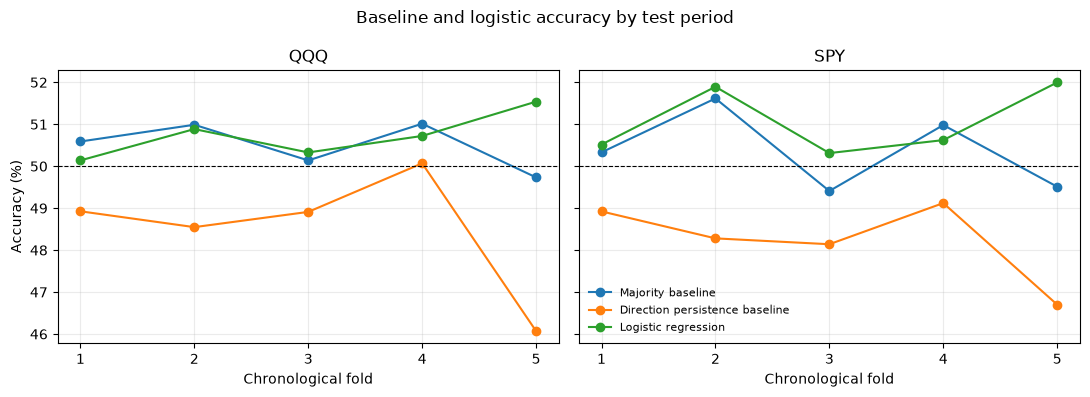

In [5]:
# Plot each model by fold so a strong average cannot hide an uneven test period.
model_order = ['Majority baseline', 'Direction persistence baseline', 'Logistic regression']
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, ticker in zip(axes, ['QQQ', 'SPY']):
    subset = fold_metrics.loc[fold_metrics['ETF'].eq(ticker)]
    for model in model_order:
        rows = subset.loc[subset['model'].eq(model)].sort_values('fold')
        axis.plot(rows['fold'], rows['accuracy'] * 100, marker='o', label=model)
    axis.axhline(50, color='black', linestyle='--', linewidth=0.8)
    axis.set_title(ticker)
    axis.set_xlabel('Chronological fold')
    axis.set_xticks(sorted(subset['fold'].unique()))
    axis.grid(alpha=0.25)
axes[0].set_ylabel('Accuracy (%)')
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle('Baseline and logistic accuracy by test period')
fig.tight_layout()
plt.show()

## Evaluation boundary

The reported metrics describe out of sample classification performance across the five test blocks. The majority baseline is refit from each training block. The persistence baseline uses only the latest completed bar. The logistic regression pipeline fits its scaler on training rows only. Transaction costs, trading rules, and profitability are not evaluated here.
